<a href="https://colab.research.google.com/github/snatzehua/bt-4012-project-2026/blob/feat--zs-exploration-00/notebooks/08_ensemble_averaging_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BT4012 · 08 · Ensemble averaging exploration

**Purpose:** explore seed averaging and cross-family blending using existing month-5 predictions from notebook 05. No model training, weight search, stacking or test evaluation.

We evaluate exactly these predeclared constructions:

1. Individual RUS CatBoost / LightGBM / XGBoost models for seeds 42, 43 and 44 (references).
2. Equal-weight CatBoost + LightGBM + XGBoost within each seed (three blends).
3. Equal-weight CatBoost across the three seeds (one three-model ensemble).
4. Equal-weight average of all nine family/seed models (one nine-model ensemble).

**Primary metric:** validation average precision (AP). Secondary metrics: recall at 5% FPR and fraud capture at 1%, 2% and 5% review capacity. This notebook evaluates fixed averages; further experiments can be planned separately based on the findings.

A mean of three individual AP values is **not** the AP of their averaged predictions. The three-model and nine-model ensembles each produce one score vector, so neither has a seed standard deviation in this experiment.

Run top to bottom in Colab or locally. Requires the saved prediction artifacts and `ensemble_input_manifest.json` from a completed notebook-05 run—not Base.csv, model packages, or notebooks 06/07.


## 1. Locations and input run

Colab defaults to `MyDrive/BT4012_grp_proj`; locally put this notebook in the repo's `notebooks/` directory. Set `LOCAL_REPO_ROOT` if needed.

Notebook 05 saves:

- `results/model_comparison/<run>/ensemble_input_manifest.json`
- `results/model_comparison/<run>/preparation_manifest.json`
- `artifacts/model_comparison/<run>/validation_index.parquet` and prediction parquet files.

If there is one eligible manifest, it is selected automatically. If there are several, the notebook lists them and asks you to set `INPUT_MANIFEST_PATH`; it never silently picks the best/latest run. Set `INPUT_ARTIFACTS_DIR` only if you moved its artifacts elsewhere. Renaming notebook 05 does not change these output paths.


In [1]:
import sys
from pathlib import Path

# Detect the runtime; local execution does not require google.colab.
IN_COLAB = 'google.colab' in sys.modules

# Colab: keep Base.csv directly inside this existing Drive project folder.
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')

# Local: normally leave None; set an absolute repo path if auto-detection fails.
LOCAL_REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    PROJECT_DIR = DRIVE_PROJECT_DIR
    RAW_PATH = PROJECT_DIR / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'processed'
else:
    if LOCAL_REPO_ROOT is not None:
        PROJECT_DIR = Path(LOCAL_REPO_ROOT).expanduser().resolve()
    else:
        working_dir = Path.cwd().resolve()
        candidates = [working_dir, *working_dir.parents]
        PROJECT_DIR = next(
            (
                candidate
                for candidate in candidates
                if (candidate / 'notebooks').is_dir()
                and (candidate / 'data').is_dir()
            ),
            working_dir,
        )

    RAW_PATH = PROJECT_DIR / 'data' / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'


# Optional explicit paths. Leave None for normal directory discovery.
INPUT_MANIFEST_PATH = None
INPUT_ARTIFACTS_DIR = None

print('Project directory:', PROJECT_DIR)


Mounted at /content/drive
Project directory: /content/drive/MyDrive/BT4012_grp_proj


## 2. Dependencies and configuration

Only analysis packages are needed. Colab installs missing packages; locally use `python -m pip install numpy pandas scikit-learn matplotlib pyarrow ipython` in your notebook environment.


In [2]:
import importlib.util
import subprocess

packages = {'numpy': 'numpy', 'pandas': 'pandas', 'sklearn': 'scikit-learn',
            'matplotlib': 'matplotlib', 'pyarrow': 'pyarrow'}
missing = [p for module, p in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    if IN_COLAB:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
    else:
        raise ImportError('Install: python -m pip install ' + ' '.join(missing))

import json
import hashlib
from datetime import datetime, timezone
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

SEEDS = [42, 43, 44]
FAMILIES = ['catboost', 'lightgbm', 'xgboost']
FPR_TARGET = 0.05
REVIEW_CAPACITIES = [0.01, 0.02, 0.05]

if INPUT_MANIFEST_PATH is None:
    choices = sorted((PROJECT_DIR / 'results' / 'model_comparison').glob('*/ensemble_input_manifest.json'))
    if len(choices) != 1:
        print('Available input manifests:')
        for choice in choices:
            print(choice)
        raise ValueError('Set INPUT_MANIFEST_PATH to one completed notebook-05 run. '
                         'If no runs appear, restore its results/artifacts folders or run notebook 05.')
    INPUT_MANIFEST_PATH = choices[0]
else:
    INPUT_MANIFEST_PATH = Path(INPUT_MANIFEST_PATH).expanduser().resolve()

input_manifest = json.loads(INPUT_MANIFEST_PATH.read_text())
prep_path = INPUT_MANIFEST_PATH.parent / 'preparation_manifest.json'
preparation = json.loads(prep_path.read_text())

# Prefer the corresponding run under the current project, for Drive/local portability.
if INPUT_ARTIFACTS_DIR is None:
    portable = PROJECT_DIR / 'artifacts' / 'model_comparison' / input_manifest['run_name']
    original = Path(input_manifest['artifacts_directory_at_creation'])
    INPUT_ARTIFACTS_DIR = portable if portable.is_dir() else original
else:
    INPUT_ARTIFACTS_DIR = Path(INPUT_ARTIFACTS_DIR).expanduser().resolve()

assert input_manifest['validation_months'] == [5]
assert input_manifest['test_evaluated'] is False
assert input_manifest['prepared_sha256'] == preparation['prepared_sha256']
ROW_ID = input_manifest['row_id_column']
TARGET = input_manifest['target_column']
MONTH = preparation['month_column']
SCORE = input_manifest['prediction_score_column']
assert ROW_ID == preparation['row_id_column'] and TARGET == preparation['target']

run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
RESULTS_DIR = PROJECT_DIR / 'results' / 'closing_ensemble' / run_id
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts' / 'closing_ensemble' / run_id
FIGURES_DIR = RESULTS_DIR / 'figures'
for directory in [RESULTS_DIR, ARTIFACTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=False)

print('Input manifest:', INPUT_MANIFEST_PATH)
print('Prediction directory:', INPUT_ARTIFACTS_DIR)
print('Results:', RESULTS_DIR)


Input manifest: /content/drive/MyDrive/BT4012_grp_proj/results/model_comparison/model_comparison_20261115T184401Z_8e91a0/ensemble_input_manifest.json
Prediction directory: /content/drive/MyDrive/BT4012_grp_proj/artifacts/model_comparison/model_comparison_20261115T184401Z_8e91a0
Results: /content/drive/MyDrive/BT4012_grp_proj/results/closing_ensemble/20261117T154928Z_7c2635


## 3. Load and align the nine prediction vectors

Read only the selected `rus10` configuration for each family. If the manifest contains multiple such configurations for a family, stop rather than select another winner using validation.

The validation index is authoritative. Match by original `row_id`, reject duplicate/missing/extra IDs, and verify labels and month after alignment. Within each seed, verify that all three families used the same training row fingerprint. Scores must be finite probabilities in [0, 1].


In [3]:
def sha256_file(path):
    """Fingerprint the actual prediction files used in this closing comparison."""
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def align_predictions(frame, index):
    """Align a score file by row ID; reject mismatched populations or labels."""
    required = [ROW_ID, MONTH, TARGET, SCORE]
    if not set(required).issubset(frame.columns):
        raise ValueError('Prediction file is missing required columns.')
    if not frame[ROW_ID].is_unique or frame[ROW_ID].isna().any():
        raise ValueError('Duplicate or null row IDs in prediction file.')
    if len(frame) != len(index) or set(frame[ROW_ID]) != set(index[ROW_ID]):
        raise ValueError('Prediction file has different validation applications.')
    aligned = frame.set_index(ROW_ID).loc[index[ROW_ID]]
    for col in [MONTH, TARGET]:
        if not np.array_equal(aligned[col].to_numpy(), index[col].to_numpy()):
            raise ValueError(f'Prediction {col} does not match the validation index.')
    scores = aligned[SCORE].to_numpy(dtype=float)
    if not np.isfinite(scores).all() or np.any((scores < 0) | (scores > 1)):
        raise ValueError('Expected finite probability scores in [0, 1].')
    return scores


index_path = INPUT_ARTIFACTS_DIR / input_manifest['validation_index_file']
validation = pd.read_parquet(index_path).sort_values(ROW_ID).reset_index(drop=True)
assert validation[ROW_ID].is_unique and not validation[ROW_ID].isna().any()
assert validation[MONTH].eq(5).all()
assert validation[TARGET].isin([0, 1]).all() and validation[TARGET].nunique() == 2
assert len(validation) == preparation['split_counts']['validation']
y_validation = validation[TARGET].to_numpy()
validation_ties = np.random.default_rng(2026).random(len(validation))

entries = pd.DataFrame(input_manifest['entries'])
selected = entries[entries.family.isin(FAMILIES) & entries.treatment.eq('rus10')].copy()
inputs, score_vectors = [], {}
for family in FAMILIES:
    family_rows = selected[selected.family.eq(family)]
    if family_rows.candidate.nunique() != 1:
        raise ValueError(f'Expected one selected RUS configuration for {family}.')
    if sorted(family_rows.seed.tolist()) != SEEDS:
        raise ValueError(f'{family} needs exactly one saved prediction for each seed {SEEDS}.')
    for row in family_rows.to_dict('records'):
        if not isinstance(row['prediction_file'], str):
            raise ValueError('Predictions were not saved in notebook 05.')
        path = INPUT_ARTIFACTS_DIR / row['prediction_file']
        key = f"{family}_seed_{row['seed']}"
        score_vectors[key] = align_predictions(pd.read_parquet(path), validation)
        inputs.append({**row, 'component': key, 'prediction_sha256': sha256_file(path)})

selected_inputs = pd.DataFrame(inputs)
assert selected_inputs.groupby('seed').training_ids_sha256.nunique().eq(1).all()
selected_inputs.to_csv(RESULTS_DIR / 'input_inventory.csv', index=False)
display(selected_inputs[['component', 'candidate', 'seed', 'prediction_file']])
print('Aligned validation applications:', len(validation))


,component,candidate,seed,prediction_file
0,catboost_seed_42,cat_d4_n600,42,cat_d4_n600_seed_42_validation.parquet
1,catboost_seed_43,cat_d4_n600,43,cat_d4_n600_seed_43_validation.parquet
2,catboost_seed_44,cat_d4_n600,44,cat_d4_n600_seed_44_validation.parquet
3,lightgbm_seed_42,lgbm_rus10,42,lgbm_rus10_seed_42_validation.parquet
4,lightgbm_seed_43,lgbm_rus10,43,lgbm_rus10_seed_43_validation.parquet
5,lightgbm_seed_44,lgbm_rus10,44,lgbm_rus10_seed_44_validation.parquet
6,xgboost_seed_42,xgb_d3_n600,42,xgb_d3_n600_seed_42_validation.parquet
7,xgboost_seed_43,xgb_d3_n600,43,xgb_d3_n600_seed_43_validation.parquet
8,xgboost_seed_44,xgb_d3_n600,44,xgb_d3_n600_seed_44_validation.parquet


Aligned validation applications: 119323


## 4. Construct only the predefined averages

Each blend averages raw probability scores from models trained at the same 10:1 sampling ratio. Different model families can still have different score scales; this experiment evaluates this fixed averaging rule, not calibrated fraud probabilities.

The nine-model average equals averaging the three within-seed blends. It costs nine base-model predictions at deployment; the CatBoost seed average costs three. Equal weights are not optimised against validation labels.


In [4]:
recipes = {key: {'kind': 'individual', 'components': [key], 'weights': [1.0]}
           for key in score_vectors}

for seed in SEEDS:
    members = [f'{family}_seed_{seed}' for family in FAMILIES]
    key = f'family_mean_seed_{seed}'
    recipes[key] = {'kind': 'within_seed_blend', 'components': members, 'weights': [1/3] * 3}
    score_vectors[key] = np.mean([score_vectors[m] for m in members], axis=0)

members = [f'catboost_seed_{seed}' for seed in SEEDS]
recipes['catboost_seed_mean'] = {'kind': 'seed_ensemble', 'components': members, 'weights': [1/3] * 3}
score_vectors['catboost_seed_mean'] = np.mean([score_vectors[m] for m in members], axis=0)

members = [f'{family}_seed_{seed}' for seed in SEEDS for family in FAMILIES]
recipes['all_nine_mean'] = {'kind': 'nine_model_ensemble', 'components': members, 'weights': [1/9] * 9}
score_vectors['all_nine_mean'] = np.mean([score_vectors[m] for m in members], axis=0)
assert np.allclose(score_vectors['all_nine_mean'],
                   np.mean([score_vectors[f'family_mean_seed_{s}'] for s in SEEDS], axis=0))


## 5. Evaluation helpers

Reuse notebook 05's metrics. Recall at 5% FPR uses the least restrictive empirical validation cutoff satisfying the ceiling. Exact review budgets use floor(capacity × applications), with the same label-independent tie breakers for every model.

The validation cutoff is recorded for reproducible comparisons and potential later evaluation. A fixed cutoff does not guarantee the same future FPR. A sampled-probability score is not a calibrated population fraud probability.


In [5]:
def at_threshold(y_true, scores, threshold):
    """
    Return confusion counts and operating metrics at an unchanged score cutoff.
    A score equal to the cutoff is flagged; divisions with zero denominators return 0.
    """
    flagged = np.asarray(scores) >= threshold
    positive = np.asarray(y_true) == 1

    tp = int(np.sum(flagged & positive))
    fp = int(np.sum(flagged & ~positive))
    fn = int(np.sum(~flagged & positive))
    tn = int(np.sum(~flagged & ~positive))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    return {
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'precision': precision,
        'recall': recall,
        'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        'fpr': fp / (fp + tn) if fp + tn else 0.0,
        'alert_rate': float(flagged.mean()),
    }


def threshold_for_fpr(y_true, scores, target_fpr):
    """
    Choose the least restrictive empirical cutoff satisfying an FPR ceiling.

    Evaluate every distinct ROC threshold on the supplied labeled split. This is
    deployable when supplied validation labels; using test labels instead defines
    a retrospective benchmark and must not be confused with a deployment threshold.
    """
    fpr, _, thresholds = roc_curve(y_true, scores, drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= target_fpr)

    return float(thresholds[eligible[-1]])


def capacity_table(y_true, scores, capacities, tie_breakers):
    """
    Evaluate fraud captured when only an exact top-scoring budget is reviewed.

    Rank by descending score, then a label-independent tie breaker. Return review
    counts, precision, recall and true/false positives standardized per 10,000 apps.
    """
    y_true = np.asarray(y_true)
    order = np.lexsort((tie_breakers, -np.asarray(scores)))
    rows = []

    for capacity in capacities:
        n_review = int(np.floor(capacity * len(y_true)))
        reviewed_labels = y_true[order[:n_review]]
        tp = int(reviewed_labels.sum())
        fp = n_review - tp
        total_frauds = int(y_true.sum())

        rows.append({
            'capacity': capacity,
            'reviews': n_review,
            'precision': tp / n_review if n_review else 0.0,
            'recall': tp / total_frauds if total_frauds else 0.0,
            'frauds_flagged': tp,
            'legitimate_reviewed': fp,
            'frauds_missed': total_frauds - tp,
            'frauds_flagged_per_10000': 10000 * tp / len(y_true),
            'legitimate_reviewed_per_10000': 10000 * fp / len(y_true),
        })

    return pd.DataFrame(rows)


def ranking_metrics(y_true, scores, model_name):
    """Return ranking metrics; recall-at-FPR uses labels from this evaluation split."""
    recall_at_fpr = np.nan

    if model_name != 'dummy':
        benchmark_threshold = threshold_for_fpr(y_true, scores, FPR_TARGET)
        recall_at_fpr = at_threshold(y_true, scores, benchmark_threshold)['recall']

    return {
        'average_precision': float(average_precision_score(y_true, scores)),
        'roc_auc': float(roc_auc_score(y_true, scores)),
        'recall_at_target_fpr_benchmark': recall_at_fpr,
    }


## 6. Evaluate, save predictions and record ensemble recipes

All candidate recipes were declared before evaluation. The highest validation AP is evidence for comparing these ensemble constructions, not an unbiased estimate of future performance. No test scores are loaded.


In [6]:
def json_safe(value):
    """Write portable JSON, including the no-alert infinite-cutoff case."""
    if isinstance(value, dict):
        return {k: json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None
    if isinstance(value, np.generic):
        return value.item()
    return value


metric_rows, capacity_rows = [], []
for name, scores in score_vectors.items():
    threshold = threshold_for_fpr(y_validation, scores, FPR_TARGET)
    operating = at_threshold(y_validation, scores, threshold)
    assert operating['fpr'] <= FPR_TARGET + 1e-12
    metric_rows.append({
        'name': name, 'kind': recipes[name]['kind'], 'n_models': len(recipes[name]['components']),
        'average_precision': average_precision_score(y_validation, scores),
        'roc_auc': roc_auc_score(y_validation, scores),
        'recall_at_5fpr': operating['recall'], 'validation_fpr': operating['fpr'],
        'validation_threshold': threshold, 'frauds_at_cutoff': operating['tp'],
    })
    capacity = capacity_table(y_validation, scores, REVIEW_CAPACITIES, validation_ties)
    capacity['name'] = name
    capacity_rows.extend(capacity.to_dict('records'))
    recipes[name].update({'validation_threshold': threshold, 'threshold_comparison': '>=',
                         'no_alert_cutoff': bool(np.isposinf(threshold))})

metrics = pd.DataFrame(metric_rows).set_index('name')
metrics.to_csv(RESULTS_DIR / 'validation_metrics.csv')
capacities = pd.DataFrame(capacity_rows)
capacities.to_csv(RESULTS_DIR / 'validation_capacity.csv', index=False)
display(metrics.sort_values('average_precision', ascending=False))

# Save only new ensemble score columns; individual inputs remain in the source run.
ensemble_predictions = validation[[ROW_ID, MONTH, TARGET]].copy()
for name, recipe in recipes.items():
    if recipe['kind'] != 'individual':
        ensemble_predictions[name] = score_vectors[name]
ensemble_predictions.to_parquet(ARTIFACTS_DIR / 'ensemble_validation_predictions.parquet', index=False)

recipe_manifest = {
    'input_manifest': str(INPUT_MANIFEST_PATH),
    'input_manifest_sha256': sha256_file(INPUT_MANIFEST_PATH),
    'validation_index_sha256': sha256_file(index_path),
    'prepared_sha256': input_manifest['prepared_sha256'],
    'validation_months': [5], 'test_evaluated': False, 'selection_metric': 'average_precision',
    'seeds': SEEDS, 'recipes': recipes, 'inputs': inputs,
    'source_specifications': input_manifest['specifications'],
    'versions': {'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__},
}
(RESULTS_DIR / 'ensemble_recipes.json').write_text(
    json.dumps(json_safe(recipe_manifest), indent=2, allow_nan=False), encoding='utf-8',
)


,kind,n_models,average_precision,roc_auc,recall_at_5fpr,validation_fpr,validation_threshold,frauds_at_cutoff
name,,,,,,,,
catboost_seed_mean,seed_ensemble,3,0.197907,0.897935,0.548547,0.049995,0.236840,774
all_nine_mean,nine_model_ensemble,9,0.197644,0.899234,0.549256,0.049995,0.237023,775
catboost_seed_42,individual,1,0.197252,0.897559,0.545712,0.049995,0.235301,770
family_mean_seed_42,within_seed_blend,3,0.196914,0.898823,0.542169,0.049995,0.235585,765
catboost_seed_43,individual,1,0.196261,0.897338,0.547838,0.049995,0.239977,773
family_mean_seed_44,within_seed_blend,3,0.196258,0.898512,0.543586,0.049995,0.239424,767
family_mean_seed_43,within_seed_blend,3,0.195931,0.899212,0.550673,0.049995,0.236668,777
catboost_seed_44,individual,1,0.194610,0.897514,0.544295,0.049995,0.238785,768
lightgbm_seed_44,individual,1,0.194066,0.896980,0.539334,0.049995,0.238639,761


11719

## 7. Explore the two ensemble questions

**A. Does averaging CatBoost seeds help?** Compare its ensemble metric with each individual and the mean of individual metrics. The mean individual metric describes a typical single fit; it is not itself a deployable predictor.

**B. Does adding model families help?** First compare each within-seed family blend with that seed's CatBoost. Then compare the nine-model average with the three-model CatBoost average, to assess the incremental value of six extra models.

Seed variation below describes the three individual fits or three within-seed blends. It is not a confidence interval; the aggregate ensembles are single evaluated predictors.


,predictor_group,evaluation,models_per_prediction,ap,ap_seed_sd,recall,recall_seed_sd
0,catboost,mean of 3 separate predictors,1,0.196041,0.001335,0.545948,0.001784
1,lightgbm,mean of 3 separate predictors,1,0.192209,0.001620,0.541224,0.005901
2,xgboost,mean of 3 separate predictors,1,0.191927,0.000826,0.542641,0.003903
3,family_mean,mean of 3 separate predictors,3,0.196368,0.000500,0.545476,0.004556
4,catboost_seed_mean,one ensemble prediction vector,3,0.197907,NaN,0.548547,NaN
5,all_nine_mean,one ensemble prediction vector,9,0.197644,NaN,0.549256,NaN


,seed,family_blend_minus_cat_ap,family_blend_minus_cat_recall,cat_seed_mean_minus_individual_ap
0,42,-0.000338,-0.003544,0.000656
1,43,-0.000329,0.002835,0.001647
2,44,0.001648,-0.000709,0.003298


capacity,0.01,0.02,0.05
name,,,
catboost_seed_42,348,492,733
catboost_seed_43,355,495,742
catboost_seed_44,342,491,738
family_mean_seed_42,355,498,736
family_mean_seed_43,357,505,742
family_mean_seed_44,352,494,735
catboost_seed_mean,354,498,734
all_nine_mean,355,499,732


Nine-model minus three-CatBoost ensemble: {'average_precision': -0.00026302255298776833, 'recall_at_5fpr': 0.0007087172218285254}


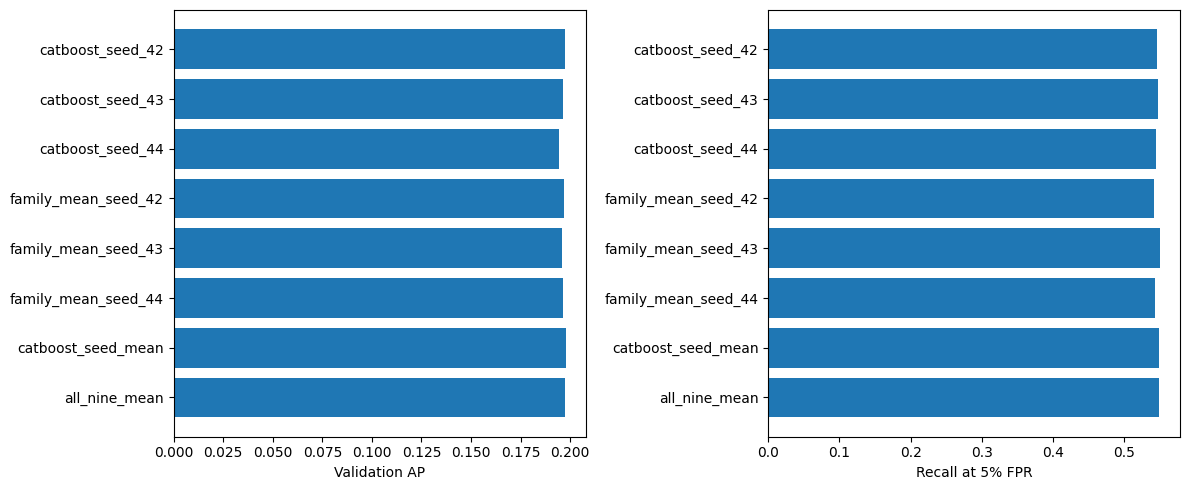

Finished without model training. Results: /content/drive/MyDrive/BT4012_grp_proj/results/closing_ensemble/20261117T154928Z_7c2635


In [7]:
summary_rows = []
for group in FAMILIES + ['family_mean']:
    keys = [f'{group}_seed_{seed}' for seed in SEEDS]
    part = metrics.loc[keys]
    summary_rows.append({'predictor_group': group, 'evaluation': 'mean of 3 separate predictors',
                         'models_per_prediction': int(part.n_models.iloc[0]),
                         'ap': part.average_precision.mean(), 'ap_seed_sd': part.average_precision.std(),
                         'recall': part.recall_at_5fpr.mean(), 'recall_seed_sd': part.recall_at_5fpr.std()})
for name in ['catboost_seed_mean', 'all_nine_mean']:
    row = metrics.loc[name]
    summary_rows.append({'predictor_group': name, 'evaluation': 'one ensemble prediction vector',
                         'models_per_prediction': int(row.n_models),
                         'ap': row.average_precision, 'ap_seed_sd': np.nan,
                         'recall': row.recall_at_5fpr, 'recall_seed_sd': np.nan})
summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS_DIR / 'closing_summary.csv', index=False)
display(summary)

paired = []
for seed in SEEDS:
    cat = metrics.loc[f'catboost_seed_{seed}']
    blend = metrics.loc[f'family_mean_seed_{seed}']
    paired.append({'seed': seed, 'family_blend_minus_cat_ap': blend.average_precision - cat.average_precision,
                   'family_blend_minus_cat_recall': blend.recall_at_5fpr - cat.recall_at_5fpr,
                   'cat_seed_mean_minus_individual_ap': metrics.loc['catboost_seed_mean', 'average_precision'] - cat.average_precision})
paired = pd.DataFrame(paired)
paired.to_csv(RESULTS_DIR / 'paired_comparisons.csv', index=False)
display(paired)

focus = ['catboost_seed_42', 'catboost_seed_43', 'catboost_seed_44',
         'family_mean_seed_42', 'family_mean_seed_43', 'family_mean_seed_44',
         'catboost_seed_mean', 'all_nine_mean']
display(capacities[capacities.name.isin(focus)].pivot(
    index='name', columns='capacity', values='frauds_flagged',
).reindex(focus))

increment = metrics.loc['all_nine_mean', ['average_precision', 'recall_at_5fpr']] - metrics.loc[
    'catboost_seed_mean', ['average_precision', 'recall_at_5fpr']]
print('Nine-model minus three-CatBoost ensemble:', increment.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, column, label in zip(axes, ['average_precision', 'recall_at_5fpr'], ['Validation AP', 'Recall at 5% FPR']):
    ax.barh(focus, metrics.loc[focus, column])
    ax.invert_yaxis()
    ax.set_xlabel(label)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'closing_ensemble_comparison.png', bbox_inches='tight')
plt.show()
print('Finished without model training. Results:', RESULTS_DIR)


## 8. Interpret the findings and plan follow-up work

- Does averaging CatBoost seeds improve AP and the operating points of interest relative to individual fits? Consider the extra three-model inference cost.
- Do cross-family blends add useful information beyond CatBoost seed averaging? Compare the incremental gains with the additional models required.
- If AP and recall disagree, retain AP as this experiment's primary criterion and describe the trade-off.
- If differences are tiny, avoid claiming a decisive improvement. This notebook does not estimate statistical significance.
- Use these results to inform further exploration, including the planned static-versus-monthly-retraining comparison. Record new hypotheses and evaluation protocols before running follow-up experiments.

To reproduce an ensemble on another authorised evaluation split, load the listed original model files (or reproduce their source configurations), align the feature schema and average predictions according to the saved recipe. No model binaries are loaded or copied here. Keep validation-based development separate from test evaluation and document the team's prior test exposure.

**Share:** this executed notebook, `closing_summary.csv`, `paired_comparisons.csv`, `validation_capacity.csv` and `ensemble_recipes.json`. Keep row-level parquet artifacts outside ordinary Git commits.

The existing output names (including `closing_summary.csv` and the `closing_ensemble` directories) are retained for compatibility with the unchanged code. They do not indicate that project exploration has ended.
